# Sprint 14 — Teste A/B do sistema de recomendações

### por Luiz Trajano

---

## O que é este documento

Uma loja virtual internacional começou um teste A/B chamado `recommender_system_test`, e a equipe anterior abandonou o projeto antes de analisar os resultados. Ficaram só a descrição técnica e os dados: os usuários que se cadastraram entre 7 e 21 de dezembro de 2020, os eventos deles até 1º de janeiro de 2021, a lista de participantes dos testes e o calendário de campanhas de marketing.

O teste dividiu novos usuários da União Europeia em dois grupos: A, o controle, e B, que recebeu a mudança. A loja esperava que, nos 14 dias depois do cadastro, o grupo B convertesse pelo menos 10% mais em cada etapa do funil: ver a página do produto, adicionar ao carrinho e comprar.

Neste notebook respondo duas perguntas, nessa ordem. Primeiro, se o teste foi feito como a especificação diz, porque um teste mal montado invalida o resultado. Depois, se o grupo B converteu melhor, com um teste Z de proporções em cada etapa. No fim, recomendo se a loja deve lançar a mudança, não lançar ou refazer o teste.

## Índice

- [0. Setup](#0.-Setup)
- [1. Objetivo do teste e hipóteses](#1.-Objetivo-do-teste-e-hipóteses)
- [2. Limitações do desenho experimental](#2.-Limitações-do-desenho-experimental)
- [3. Diagnóstico e limpeza dos dados](#3.-Diagnóstico-e-limpeza-dos-dados)
- [4. O teste seguiu a especificação?](#4.-O-teste-seguiu-a-especificação?)
- [5. Análise exploratória (EDA)](#5.-Análise-exploratória-(EDA))
- [6. Teste A/B](#6.-Teste-A/B)
- [7. Conclusão geral](#7.-Conclusão-geral)

---

# 0. Setup

Neste Setup importo as bibliotecas, aplico o meu estilo de gráficos e leio os 4 arquivos, cada um numa célula com um nome curto: `marketing`, `users`, `events` e `participants`. Na plataforma o caminho começa com `/datasets/`; na minha máquina, os arquivos ficam na pasta `data/`. O `info()` e o `sample()` dão a primeira vista de cada arquivo, e uma célula conta os nulos. A limpeza fica para a seção 3, e as constantes ficam na célula onde são usadas.

In [453]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from scipy import stats
import math as mth

pd.set_option('display.max_columns', None)

# --- Meu estilo visual (padrão das Sprints 11 e 13) ---
meu_estilo = {
    'figure.figsize':   (12, 5),
    'figure.facecolor': '#0d0d0d',
    'axes.facecolor':   '#0d0d0d',
    'savefig.facecolor':'#0d0d0d',
    'axes.edgecolor':   '#333333',
    'axes.labelcolor':  '#aaaaaa',
    'axes.titlecolor':  '#ffffff',
    'text.color':       '#aaaaaa',
    'xtick.color':      '#aaaaaa',
    'ytick.color':      '#aaaaaa',
    'grid.color':       '#222222',
    'axes.grid':        True,
    'axes.grid.axis':   'y',
    'axes.axisbelow':   True,
    'axes.prop_cycle':  cycler(color=['#5B6BF5', '#FF6B6B', '#F5A623', '#4ECDC4', '#C77DFF']),
    'savefig.dpi':      150,
    'savefig.bbox':     'tight',
    'legend.facecolor': '#1a1a1a',
    'legend.edgecolor': '#333333',
}
sns.set_theme(style='dark', rc=meu_estilo)   # seaborn primeiro, meu rc por cima
plt.rcParams.update(meu_estilo)
CORES = ['#5B6BF5', '#FF6B6B', '#F5A623', '#4ECDC4', '#C77DFF']

### 1. `marketing` (ab_project_marketing_events_us.csv)

In [454]:
try:
    marketing = pd.read_csv('/datasets/ab_project_marketing_events_us.csv')
except FileNotFoundError:
    # na minha máquina os arquivos ficam na pasta data
    marketing = pd.read_csv('data/ab_project_marketing_events_us.csv')

marketing.info()
marketing.sample(5, random_state=42)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   name       14 non-null     object
 1   regions    14 non-null     object
 2   start_dt   14 non-null     object
 3   finish_dt  14 non-null     object
dtypes: object(4)
memory usage: 580.0+ bytes


,name,regions,start_dt,finish_dt
9,Victory Day CIS (May 9th) Event,CIS,2020-05-09,2020-05-11
11,Dragon Boat Festival Giveaway,APAC,2020-06-25,2020-07-01
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03
12,Single's Day Gift Promo,APAC,2020-11-11,2020-11-12
5,Black Friday Ads Campaign,"EU, CIS, APAC, N.America",2020-11-26,2020-12-01


### 2. `users` (final_ab_new_users_upd_us.csv)

In [455]:
try:
    users = pd.read_csv('/datasets/final_ab_new_users_upd_us.csv')
except FileNotFoundError:
    # na minha máquina os arquivos ficam na pasta data
    users = pd.read_csv('data/final_ab_new_users_upd_us.csv')

users.info()
users.sample(5, random_state=42)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58703 entries, 0 to 58702
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     58703 non-null  object
 1   first_date  58703 non-null  object
 2   region      58703 non-null  object
 3   device      58703 non-null  object
dtypes: object(4)
memory usage: 1.8+ MB


,user_id,first_date,region,device
11902,D69DF1D8D4BC6484,2020-12-21,EU,Mac
48700,18CE677C4733D3E0,2020-12-19,EU,PC
52295,4E3D3900B43B4349,2020-12-13,N.America,iPhone
34065,2E89A43520C059FA,2020-12-10,EU,PC
33116,B9F3341D45A22D68,2020-12-10,EU,iPhone


### 3. `events` (final_ab_events_upd_us.csv)

In [456]:
try:
    events = pd.read_csv('/datasets/final_ab_events_upd_us.csv')
except FileNotFoundError:
    # na minha máquina os arquivos ficam na pasta data
    events = pd.read_csv('data/final_ab_events_upd_us.csv')

events.info()
events.sample(5, random_state=42)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423761 entries, 0 to 423760
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   user_id     423761 non-null  object 
 1   event_dt    423761 non-null  object 
 2   event_name  423761 non-null  object 
 3   details     60314 non-null   float64
dtypes: float64(1), object(3)
memory usage: 12.9+ MB


,user_id,event_dt,event_name,details
49004,5BC4E7137B00CFDD,2020-12-23 06:26:09,purchase,4.99
238603,7145D9F3180DB08E,2020-12-29 07:30:43,product_page,NaN
10009,B9C56939210A8795,2020-12-12 23:37:26,purchase,4.99
129476,AA9CA6837B1550BE,2020-12-09 20:34:04,product_page,NaN
204231,8588FF210CFB8E77,2020-12-21 07:43:13,product_page,NaN


### 4. `participants` (final_ab_participants_upd_us.csv)

In [457]:
try:
    participants = pd.read_csv('/datasets/final_ab_participants_upd_us.csv')
except FileNotFoundError:
    # na minha máquina os arquivos ficam na pasta data
    participants = pd.read_csv('data/final_ab_participants_upd_us.csv')

participants.info()
participants.sample(5, random_state=42)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
dtypes: object(3)
memory usage: 340.6+ KB


,user_id,group,ab_test
9349,E0F6A9ACBA17FFA1,B,interface_eu_test
6176,70FE64008F8E2E53,A,interface_eu_test
13422,2E92C793C6EF61CB,A,interface_eu_test
9623,5621ED854DA02076,A,interface_eu_test
2231,C8ABA13613426B05,B,recommender_system_test


In [458]:
# nulos de cada arquivo: quantidade e percentual
# noto logo de cara que tínhamos o events com nulos
# ainda assim verifico todos os arquivos em código porque posso ter visto errado algo
for nome, tabela in {'marketing': marketing, 'users': users, 'events': events, 'participants': participants}.items():
    nulos = tabela.isna().sum()
    nulos = nulos[nulos > 0]
    print(f'--- {nome}')
    if nulos.empty:
        print('sem nulos')
    else:
        print(pd.DataFrame({'nulos': nulos, '%': (nulos / len(tabela) * 100).round(2)}))

--- marketing
sem nulos
--- users
sem nulos
--- events
          nulos      %
details  363447  85.77
--- participants
sem nulos


**Conclusão 0 — os 4 arquivos carregam, mas as datas e as colunas de categoria vêm como texto:**

+ **marketing:** 14 linhas e 4 colunas, uma campanha por linha, sem nulos e com 580 bytes de memória. As datas de início e fim (`start_dt`, `finish_dt`) estão como `object` e precisam virar `datetime`. `name` e `regions` também estão como texto: confiro quantos valores únicos têm para ver se vale transformar em `category`.

+ **users:** 58.703 linhas e 4 colunas, um usuário cadastrado por linha, sem nulos e com 1,8 MB. A data de cadastro (`first_date`) precisa virar `datetime`. `region` e `device` parecem ter poucos valores repetidos, então confiro os únicos e transformo em `category`.

+ **events:** 423.761 linhas e 4 colunas, um evento por linha, com 12,9 MB, o maior arquivo. A data do evento (`event_dt`) tem hora e precisa virar `datetime` mantendo a hora. `event_name` se repete no `sample()` e está como `object`, então é candidata a `category`. A coluna `details` tem só 60.314 valores preenchidos e 363.447 nulos (85,77%). Suspeito que seja característica e não erro, porque o enunciado diz que ela guarda o valor do pedido em `purchase`. Confiro isto.

+ **participants:** 14.525 linhas e 3 colunas, um usuário num teste e num grupo por linha, sem nulos e com 340,6 KB. `group` e `ab_test` são candidatas a `category`: confiro os valores únicos de cada uma para ver se aparece algo além dos grupos A e B e do teste `recommender_system_test`.

+ **Memória:** os valores acima são os do `info()`, que não conta todo o texto das colunas `object` (por isso o "+"). Para comparar antes e depois das conversões, uso `memory_usage(deep=True)` na seção 3.

**O que levo para a seção 3:** converter as 4 colunas de data para `datetime`, conferir os valores únicos das colunas de texto e converter as repetitivas para `category`, confirmar se os nulos de `details` estão só fora de `purchase` e medir a memória antes e depois.

---

# 1. Objetivo do teste e hipóteses

> **Enunciado:** explicar com as minhas palavras o objetivo do experimento e formular a hipótese associada a ele.

## 1.1 O que o teste quer provar

A loja mudou algo na experiência de compra de parte dos novos usuários da União Europeia e quer saber se essa mudança faz mais gente avançar no funil. Os usuários foram divididos em dois grupos: o A vê a loja como sempre foi (controle) e o B vê a versão nova (teste). A loja espera que, nos 14 dias depois do cadastro, o grupo B tenha uma conversão pelo menos 10% maior que a do A em cada etapa: ver a página do produto (`product_page`), adicionar ao carrinho e comprar (`purchase`).

Há uma incoerência na descrição técnica. O grupo B é chamado de "novo funil de pagamento", mas o objetivo do teste fala em "sistema aprimorado de recomendações". As duas mudanças agiriam em etapas diferentes: recomendações devem levar mais gente à página do produto e ao carrinho, e um novo pagamento deve agir na compra. Como não sei qual das duas foi testada, analiso as três etapas e registro essa dúvida nas limitações, conferindo-as a fundo.

## 1.2 Hipóteses por etapa do funil

Em cada etapa comparo a proporção de usuários de cada grupo que chegou até ela nos 14 dias depois do cadastro:

| Etapa | H0 | H1 |
|---|---|---|
| `product_page` | a proporção de usuários que viu a página do produto é igual em A e B | é diferente |
| carrinho | a proporção de usuários que adicionou ao carrinho é igual em A e B | é diferente |
| `purchase` | a proporção de usuários que comprou é igual em A e B | é diferente |

Uso hipóteses bilaterais: a pergunta é se B difere de A, e escolher a direção depois de ver os números seria enviesar o teste. Se houver diferença, comparo o tamanho dela com o aumento de 10% esperado.

São três comparações com os mesmos usuários, e quem chega ao carrinho também está entre quem viu o produto. Por isso uso a correção de Bonferroni, que divide o nível de significância de 5% por 3 e não exige que os testes sejam independentes.

---

# 2. Limitações do desenho experimental

> **Enunciado:** descrever as limitações que, na minha opinião, existem no desenho e podem influenciar os resultados.

## 2.1 Antes de abrir os dados

Lendo só a descrição técnica, vejo seis pontos que podem distorcer o resultado:

1. **Natal e Ano-Novo dentro do teste. Aprtir das épocas e a influência nas compras** O teste vai de 07/12/2020 a 01/01/2021. Nessa época as pessoas compram presentes e mudam de hábito, então a conversão pode não representar um mês comum (hipoteticamente falando até se comprovar em código).
2. **Janela de 14 dias cortada.** Os cadastros vão até 21/12, mas os dados acabam em 01/01. Quem se cadastrou depois de 18/12 não teve os 14 dias inteiros para converter, e isso puxa a conversão para baixo nos dois grupos.
3. **Campanhas de marketing no período.** Uma campanha que atinja a EU pode aumentar os eventos de todo mundo. Se ela atingir um grupo mais que o outro, a diferença entre A e B deixa de ser só efeito do teste.
4. **Não sei o que o grupo B recebeu.** O grupo se chama "novo funil de pagamento" e o objetivo fala em "sistema de recomendações". Sem saber qual foi a mudança, fica difícil dizer em qual etapa esperar o efeito.
5. **Outro teste ao mesmo tempo.** Se houver um teste rodando em paralelo com os mesmos usuários, quem caiu no grupo de mudança do outro teste pode ter o comportamento alterado por ele, e não por este.
6. **Tamanho e público.** O teste previa 6.000 participantes e 15% dos novos usuários da EU. Se a amostra real for menor, o teste perde poder para detectar um aumento de 10%. Se incluir usuários de fora da EU, o resultado deixa de valer para o público planejado.

## 2.2 Confirmadas pelos dados

A seção 4 conferiu cada ponto da 2.1 nos dados. Cinco das seis limitações se confirmaram, e apareceram duas que eu não tinha previsto:

| Limitação | O que os dados mostraram | Efeito no teste |
|---|---|---|
| 1. Natal e Ano-Novo | o teste cobre de 07/12 a 30/12, com as festas dentro (seção 4.3) | a conversão pode não representar um mês comum |
| 2. Janela de 14 dias cortada | os dados acabam em 30/12, e não em 01/01: 1.170 participantes (38,36%) não tiveram os 14 dias (seção 4.3) | a conversão medida fica abaixo da real |
| 3. Campanhas no período | a "Christmas&New Year Promo" atinge a EU de 25/12 a 03/01 (seção 4.2) | pode mudar o comportamento de todos no fim do teste; vale para os dois grupos |
| 4. O que o grupo B recebeu | os dados não dizem; o nome do grupo e o objetivo continuam incoerentes | não dá para saber em qual etapa esperar o efeito |
| 5. Outro teste ao mesmo tempo | 887 participantes (24,14%) também estavam no `interface_eu_test`; saíram os 431 (11,73%) do grupo B de lá (seção 4.1) | a amostra encolhe |
| 6. Tamanho e público | 194 participantes (5,98%) de fora da EU saíram; ficaram 3.050, 50,83% dos 6.000 previstos; o teste recebeu 8,82% dos novos usuários da EU, contra 15% (seção 4.2) | o teste perde poder para detectar um aumento de 10% |
| Nova: grupos desequilibrados | 74,72% no A e 25,28% no B, e o qui-quadrado contra 50/50 dá p-valor de 3,64e-164 (seção 4.2) | o sorteio não foi meio a meio ou o B perdeu usuários; o B pequeno tira poder e a comparação pode estar enviesada |
| Nova: corte de tempo desigual | 42,04% do A não teve os 14 dias, contra 27,50% do B (seção 4.3) | o A tende a converter menos pelo calendário, o que favorece o B; por isso o teste Z roda em duas versões na seção 6 |

Juntas, essas limitações dizem que o teste não foi feito como a especificação previa. O resultado da seção 6 vale como indício, e não como prova definitiva de que a mudança funciona ou não.

---

# 3. Diagnóstico e limpeza dos dados

> **Enunciado:** diagnóstico inicial e plano de processamento e limpeza (tipos, ausentes, duplicados, inconsistências).

## 3.1 Tipos de dados

> *Enunciado: "É necessário converter os tipos de dados?"*

Antes de converter, confiro os valores únicos das colunas de texto: coluna com poucos valores repetidos vira `category`, que ocupa menos memória e deixa claro que é uma categoria. As quatro colunas de data viram `datetime`, com o formato declarado para o pandas não ter de adivinhar, e `event_dt` mantém a hora. Meço a memória real com `memory_usage(deep=True)` antes e depois, como planejei na Conclusão 0.

In [459]:
# 1. valores únicos das colunas de texto: poucos valores repetidos indicam que 
# a coluna pode virar category
# confiro em cada um com um for para evitar código longo e muitas células
tabelas = {'marketing': marketing, 'users': users, 'events': events, 'participants': participants}
colunas_texto = {'marketing': ['name', 'regions'], 'users': ['region', 'device'],
                'events': ['event_name'], 'participants': ['group', 'ab_test']}
# laço duplo: .items() devolve os pares (nome da tabela, lista de colunas)
# cada coluna vira um dicionário com o resumo, guardado na lista resumo_unicos
resumo_unicos = []
for nome, colunas in colunas_texto.items():
    for coluna in colunas:
        unicos = tabelas[nome][coluna].unique()
        resumo_unicos.append({'tabela': nome,
                            'coluna': coluna,
                            'únicos': len(unicos),
                            'linhas': len(tabelas[nome])})

# a lista vira tabela: poucos únicos em muitas linhas indicam que a coluna pode virar category
display(pd.DataFrame(resumo_unicos))

# os valores de cada coluna, abaixo da tabela
for nome, colunas in colunas_texto.items():
    for coluna in colunas:
        print(f'{nome}.{coluna}: {list(tabelas[nome][coluna].unique())}')

,tabela,coluna,únicos,linhas
0,marketing,name,14,14
1,marketing,regions,6,14
2,users,region,4,58703
3,users,device,4,58703
4,events,event_name,4,423761
5,participants,group,2,14525
6,participants,ab_test,2,14525


marketing.name: ['Christmas&New Year Promo', "St. Valentine's Day Giveaway", "St. Patric's Day Promo", 'Easter Promo', '4th of July Promo', 'Black Friday Ads Campaign', 'Chinese New Year Promo', 'Labor day (May 1st) Ads Campaign', "International Women's Day Promo", 'Victory Day CIS (May 9th) Event', 'CIS New Year Gift Lottery', 'Dragon Boat Festival Giveaway', "Single's Day Gift Promo", 'Chinese Moon Festival']
marketing.regions: ['EU, N.America', 'EU, CIS, APAC, N.America', 'N.America', 'APAC', 'EU, CIS, APAC', 'CIS']
users.region: ['EU', 'N.America', 'APAC', 'CIS']
users.device: ['PC', 'Android', 'iPhone', 'Mac']
events.event_name: ['purchase', 'product_cart', 'product_page', 'login']
participants.group: ['A', 'B']
participants.ab_test: ['recommender_system_test', 'interface_eu_test']


In [460]:
# 2. memória real antes: deep=True conta o texto das colunas object, que o info() deixa de fora
# calcula a memória usada por cada tabela antes das conversões em MB
memoria_antes = pd.Series({nome: tabela.memory_usage(deep=True).sum() / 1024**2
                        for nome, tabela in tabelas.items()})

# datas para datetime com o formato declarado; event_dt mantém a hora
# mantenho mesmo format para cada uma e assim termos um padrão
marketing['start_dt'] = pd.to_datetime(marketing['start_dt'], format='%Y-%m-%d')
marketing['finish_dt'] = pd.to_datetime(marketing['finish_dt'], format='%Y-%m-%d')
users['first_date'] = pd.to_datetime(users['first_date'], format='%Y-%m-%d')
events['event_dt'] = pd.to_datetime(events['event_dt'], format='%Y-%m-%d %H:%M:%S')

# colunas com poucos valores repetidos viram category
# name (um valor por campanha) e regions (combinações de regiões em texto) ficam como texto,
# pois apresentam poucos valores únicos.
# e guarda várias regiões numa frase ("EU,N.America"), e na seção 4 procuro "EU" dentro do
# texto (assim facilito o que vier a frente). 
# Como category, essa busca fica mais trabalhosa e a economia em 14 linhas é nula
users[['region', 'device']] = users[['region', 'device']].astype('category')
events['event_name'] = events['event_name'].astype('category')
participants[['group', 'ab_test']] = participants[['group', 'ab_test']].astype('category')

# memória depois: as tabelas do dicionário são as mesmas, já convertidas
memoria_depois = pd.Series({nome: tabela.memory_usage(deep=True).sum() / 1024**2
                            for nome, tabela in tabelas.items()})
pd.DataFrame({'antes (MB)': memoria_antes.round(3),
            'depois (MB)': memoria_depois.round(3),
              'redução %': ((1 - memoria_depois / memoria_antes) * 100).round(1)})

,antes (MB),depois (MB),redução %
marketing,0.003,0.002,39.1
users,12.897,4.200,67.4
events,80.186,33.139,58.7
participants,2.528,0.929,63.3


In [461]:
# conferência depois da conversão: dtypes mostra o tipo de cada coluna
# datas devem aparecer como datetime e as 5 colunas convertidas como category
# uso o for anterior como base e economizo linhas de código
for nome, tabela in tabelas.items():
    print(f'--- {nome}')
    print(tabela.dtypes)

--- marketing
name                 object
regions              object
start_dt     datetime64[ns]
finish_dt    datetime64[ns]
dtype: object
--- users
user_id               object
first_date    datetime64[ns]
region              category
device              category
dtype: object
--- events
user_id               object
event_dt      datetime64[ns]
event_name          category
details              float64
dtype: object
--- participants
user_id      object
group      category
ab_test    category
dtype: object


**Conclusão 3.1 — as datas viraram datetime e as colunas repetitivas viraram category, com até 67,4% menos memória:**

+ **Valores únicos:** `region` e `device` têm 4 valores cada, `event_name` tem 4, `group` tem 2 (A e B) e `ab_test` tem 2. Essas viraram `category`. `name` tem 14 valores para 14 campanhas, um por linha, e fica como texto. `regions` guarda combinações de regiões numa frase só ("EU, N.America") e fica como texto, porque na seção 4 procuro "EU" dentro dela.

+ **Nome do evento de carrinho:** nos dados ele é `product_cart`, e não `product_card` como no enunciado do Notion. Uso `product_cart` daqui em diante. Existe também o evento `login`, que não faz parte do funil.

+ **Dois testes em `participants`:** `ab_test` tem `recommender_system_test` e `interface_eu_test`. O segundo é o teste paralelo que a limitação 5 previa, e trato isso na seção 4.1.

+ **Memória real:** `users` caiu de 12,9 MB para 4,2 MB (67,4%), `events` de 80,19 MB para 33,14 MB (58,7%) e `participants` de 2,53 MB para 0,93 MB (63,3%). `marketing` é pequeno demais para fazer diferença. A memória real de `events` era bem maior que os 12,9 MB do `info()`, o que confirma que o "+" escondia o texto das colunas `object`.

+ **Cuidado para as próximas seções:** em `groupby` com coluna `category`, uso `observed=True` para o pandas não criar grupos vazios.

## 3.2 Ausentes, duplicados e limpeza

> *Enunciado: "Há valores ausentes ou duplicados? Como você os caracterizaria?"*

Os nulos já apareceram no Setup: só `details`, em `events`, onde estava evidente. Aqui confiro se eles são característica ou erro, cruzando com `event_name`. Para os duplicados, uma função com docstring olha as linhas inteiras e as chaves de cada arquivo, chamada num laço. Repetição de chave nem sempre é erro: em `participants`, o mesmo usuário pode aparecer em dois testes, então olho também a combinação de usuário e teste. Só removo linhas se encontrar erro.

In [462]:
# função que confere linhas inteiras e chaves repetidas de uma tabela
# escrevo a checagem uma vez só e chamo para as 4 tabelas no laço: ganho tempo,
# evito copiar o mesmo bloco 4 vezes e, se precisar mudar algo, mudo num lugar só
def resumo_duplicados(nome, tabela, chaves):
    """Mostra quantas linhas inteiras e quantas chaves se repetem numa tabela.

    Parâmetros
    ----------
    nome : nome da tabela, para o print.
    tabela : DataFrame a conferir.
    chaves : lista de listas de colunas; cada lista é uma chave que deveria ser única.

    Retorna
    -------
    None : imprime o total e o percentual de cada checagem.
    """
    linhas = tabela.duplicated()
    print(f'--- {nome}: {linhas.sum()} linhas inteiras repetidas ({linhas.mean():.2%})')
    # duplicated(subset=chave) compara só as colunas da chave, não a linha inteira
    # ex.: chave ['user_id', 'ab_test'] marca True quando o mesmo usuário aparece de novo 
    # no mesmo teste
    for chave in chaves:
        repetidos = tabela.duplicated(subset=chave)
        # sum() conta os True (quantos repetidos) e mean() dá a proporção
        print(f'    chave {chave}: {repetidos.sum()} repetidos ({repetidos.mean():.2%})')


# 1. as chaves de cada tabela; events não tem chave única (um usuário tem vários eventos)
chaves_por_tabela = {'marketing': [['name']],
                    'users': [['user_id']],
                    'events': [],
                    'participants': [['user_id'], ['user_id', 'ab_test']]}
# .items() devolve os pares (nome da tabela, lista de chaves) do dicionário chaves_por_tabela
# tabelas[nome] busca o DataFrame pelo nome e a função confere as chaves dele
for nome, chaves in chaves_por_tabela.items():
    resumo_duplicados(nome, tabelas[nome], chaves)

--- marketing: 0 linhas inteiras repetidas (0.00%)
    chave ['name']: 0 repetidos (0.00%)
--- users: 0 linhas inteiras repetidas (0.00%)
    chave ['user_id']: 0 repetidos (0.00%)
--- events: 0 linhas inteiras repetidas (0.00%)
--- participants: 0 linhas inteiras repetidas (0.00%)
    chave ['user_id']: 887 repetidos (6.11%)
    chave ['user_id', 'ab_test']: 0 repetidos (0.00%)


In [463]:
# 2. nulos de details por event_name: crosstab conta os eventos em cada combinação
# isna() marca True onde falta valor; o map troca True/False por 'sem valor'/'com valor'
# se só purchase tiver valor, o nulo é característica (valor do pedido), não erro
pd.crosstab(events['event_name'],
            events['details'].isna().map({False: 'com valor', True: 'sem valor'}))

details,com valor,sem valor
event_name,,
login,0,182465
product_cart,0,60120
product_page,0,120862
purchase,60314,0


**Conclusão 3.2 — não há duplicado nem ausente que seja erro, e nenhuma linha precisa sair:**

+ **Duplicados:** nenhum dos 4 arquivos tem linha inteira repetida, e o `user_id` é único em `users`. Em `participants`, o `user_id` se repete 887 vezes (6,11%), mas a combinação de `user_id` e `ab_test` não se repete nenhuma vez. Então não é duplicação: são usuários que estão nos dois testes ao mesmo tempo. É a contaminação que irei tratar.

+ **Ausentes em `details`:** os 60.314 valores preenchidos estão todos em `purchase`, e nenhum evento de outro tipo tem valor. O nulo é característica do dado, porque só a compra tem valor de pedido. Mantenho os nulos.

+ **Limpeza:** nenhuma linha sai nesta seção. Os filtros que mudam a base (teste certo, usuários contaminados, região e janela de 14 dias) ficam na seção 4, onde cada um é conferido contra a especificação.

---

# 4. O teste seguiu a especificação?

> **Enunciado:** antes de avaliar o resultado, conferir se o teste foi feito como a descrição técnica diz. Cada desvio vira número, decisão e entrada nas limitações (2.2).

## 4.1 Teste certo e contaminação

> *Enunciado: "Existem usuários presentes em ambos os grupos?"*

Primeiro separo só os participantes do `recommender_system_test`, porque `participants` traz também o `interface_eu_test` (seção 3.1). Depois procuro dois tipos de contaminação: usuário que caiu nos grupos A e B deste teste, e usuário que também está no teste paralelo. Quem está no grupo A do teste paralelo não recebeu nenhuma mudança lá, então não atrapalha. Quem está no grupo B do teste paralelo viu outra mudança ao mesmo tempo, e o comportamento dele pode vir dela. Por isso removo só esse grupo, e não todos os 887.

In [464]:
# 1. filtro só o recommender_system_test: participants também traz o interface_eu_test (seção 3.1)
# .copy() cria uma tabela nova, para os filtros seguintes não mexerem em participants
teste = participants[participants['ab_test'] == 'recommender_system_test'].copy()
print(f'participantes do recommender_system_test: {len(teste)} de {len(participants)} '
      f'({len(teste) / len(participants):.2%})')
teste['group'].value_counts()

participantes do recommender_system_test: 3675 de 14525 (25.30%)


group
A    2747
B     928
Name: count, dtype: int64

In [465]:
# 2. usuário nos dois grupos do mesmo teste: nunique() conta quantos grupos cada usuário tem
# trago o teste que fiz a cópia pra não mexer no original
# O .index pega só os IDs, sem os números
grupos_por_usuario = teste.groupby('user_id')['group'].nunique()
nos_dois_grupos = grupos_por_usuario[grupos_por_usuario > 1].index
print(f'usuários nos grupos A e B ao mesmo tempo: {len(nos_dois_grupos)}')

# 3. usuários que também estão no teste paralelo, com o grupo que receberam lá
#    suffixes separa a coluna group dos dois testes depois do merge
paralelo = participants.loc[participants['ab_test'] == 'interface_eu_test', ['user_id', 'group']]
nos_dois_testes = teste.merge(paralelo, on='user_id', suffixes=('_recomendacao', '_paralelo'))
print(f'usuários também no interface_eu_test: {len(nos_dois_testes)} ({len(nos_dois_testes) / len(teste):.2%})')

# crosstab: grupo neste teste (linhas) contra grupo no teste paralelo (colunas)
pd.crosstab(nos_dois_testes['group_recomendacao'], nos_dois_testes['group_paralelo'])

usuários nos grupos A e B ao mesmo tempo: 0
usuários também no interface_eu_test: 887 (24.14%)


group_paralelo,A,B
group_recomendacao,,
A,340,325
B,116,106


In [466]:
# 4. decisão: saem quem está nos dois grupos e quem recebeu a mudança do teste paralelo 
# (grupo B de lá)
contaminados = nos_dois_testes.loc[nos_dois_testes['group_paralelo'] == 'B', 'user_id']
remover = teste['user_id'].isin(nos_dois_grupos) | teste['user_id'].isin(contaminados)
print(f'removidos: {remover.sum()} ({remover.mean():.2%}) | ficam: {(~remover).sum()}')

teste = teste[~remover]
display(teste['group'].value_counts())

removidos: 431 (11.73%) | ficam: 3244


group
A    2422
B     822
Name: count, dtype: int64

**Conclusão 4.1 — o teste certo tem 3.675 participantes, e saem 431 que viram a mudança de outro teste:**

+ **Teste certo:** dos 14.525 registros de `participants`, 3.675 (25,30%) são do `recommender_system_test`, o teste que a especificação descreve. Já aqui os grupos são desiguais: 2.747 no A e 928 no B.

+ **Nos grupos A e B ao mesmo tempo:** nenhum usuário.

+ **Um segundo teste no mesmo período:** `participants` traz também o `interface_eu_test`, que o enunciado não menciona. 887 participantes do `recommender_system_test` (24,14%) estavam nele também, e o cruzamento mostra o grupo de cada um nos dois:

| Grupo no `recommender_system_test` | `interface_eu_test` grupo A (controle, sem mudança) | `interface_eu_test` grupo B (recebeu a mudança de lá) |
|---|---|---|
| A (controle) | 340 | 325 |
| B (teste) | 116 | 106 |

+ **Quem fica e quem sai:** o grupo A do `interface_eu_test` é o controle daquele teste e não viu nada diferente, então esses usuários ficam. O grupo B do `interface_eu_test` recebeu uma mudança que não é a avaliada aqui. Os 325 do grupo A deixam de ser um controle puro, porque não viram a loja de sempre. Os 106 do grupo B viram as duas mudanças juntas, e não dá para saber qual delas mudou o comportamento.

+ **Decisão:** removo os 431 participantes (11,73%) que estavam no grupo B do `interface_eu_test`. Assim, a única diferença entre os grupos A e B é a mudança do `recommender_system_test`. Ficam 3.244: 2.422 no A e 822 no B. Remover os 887 tiraria quase um quarto da amostra sem motivo, porque 456 deles não viram mudança nenhuma no outro teste. Essa sobreposição confirma a limitação 5 da seção 2.1.

## 4.2 Região, datas, tamanho e campanhas

Junto `teste` com `users` para ter a região e a data de cadastro de cada participante. Confiro cada ponto da especificação e guardo os valores dela em constantes nesta célula: região EU, cadastro entre 07/12 e 21/12, 6.000 participantes previstos e 15% dos novos usuários da EU. Quem estiver fora da EU sai, porque o teste foi desenhado só para ela. No fim, vejo quais campanhas de marketing cruzam o período do teste e atingem a EU.

In [467]:
# 1. região e data de cadastro de cada participante; how='left' mantém todos do teste
teste = teste.merge(users, on='user_id', how='left')
print(f'participantes sem cadastro em users: {teste["first_date"].isna().sum()}')

# 2. região: o teste é só para a região EU (o valor 'EU' da coluna region)
fora_eu = teste['region'] != 'EU'
print(f'fora da EU: {fora_eu.sum()} ({fora_eu.mean():.2%})')
print(teste.loc[fora_eu, 'region'].value_counts())
teste = teste[~fora_eu]

participantes sem cadastro em users: 0
fora da EU: 194 (5.98%)
region
N.America    119
APAC          45
CIS           30
EU             0
Name: count, dtype: int64


In [468]:
# 3. datas de cadastro e tamanho, contra a especificação
# crio as constantes para o período de cadastro e o tamanho esperado do teste
# defino-as antes para facilitar a lógica e possíveis alterações futuras
INICIO_CADASTRO = pd.Timestamp('2020-12-07')
FIM_CADASTRO = pd.Timestamp('2020-12-21')
PARTICIPANTES_PREVISTOS = 6000
PARCELA_PREVISTA = 0.15

fora_periodo = ~teste['first_date'].between(INICIO_CADASTRO, FIM_CADASTRO) #uso between para verificar se a data está dentro do período
print(f'cadastros de {teste["first_date"].min()} a {teste["first_date"].max()} | '
      f'fora do período: {fora_periodo.sum()}')
print(f'participantes: {len(teste)} de {PARTICIPANTES_PREVISTOS} previstos '
      f'({len(teste) / PARTICIPANTES_PREVISTOS:.2%})')

# 4. parcela dos novos usuários da EU: todos os participantes da EU do teste, antes dos filtros,
#    sobre todos os novos usuários da EU cadastrados no período
novos_eu = users[(users['region'] == 'EU') & users['first_date'].between(INICIO_CADASTRO, FIM_CADASTRO)]
teste_eu_original = participants[participants['ab_test'] == 'recommender_system_test'].merge(users, on='user_id')
teste_eu_original = teste_eu_original[teste_eu_original['region'] == 'EU']
print(f'parcela dos novos usuários da EU no teste: {len(teste_eu_original)} de {len(novos_eu)} '
      f'({len(teste_eu_original) / len(novos_eu):.2%}), previsto: {PARCELA_PREVISTA:.0%}')

cadastros de 2020-12-07 00:00:00 a 2020-12-21 00:00:00 | fora do período: 0
participantes: 3050 de 6000 previstos (50.83%)
parcela dos novos usuários da EU no teste: 3481 de 39466 (8.82%), previsto: 15%


In [469]:
# 5. o desequilíbrio entre A e B é acaso? qui-quadrado de aderência contra a divisão 50/50
#    compara a contagem observada (contagem_grupos) com a esperada (metade para cada grupo)
#    devolve a estatística (distância entre observado e esperado) e o p-valor (chance de ser acaso)
#    H0: divisão 50/50; p-valor abaixo de 0,05 rejeita H0
contagem_grupos = teste['group'].value_counts()
esperado = [len(teste) / 2, len(teste) / 2]
# f_exp=esperado: o que deveria ter acontecido num sorteio meio a meio, 
# que é 3.050 / 2 = 1.525 em cada grupo. f_exp quer dizer "frequências esperadas".
estatistica, p_valor = stats.chisquare(contagem_grupos, f_exp=esperado)
print(f'A: {contagem_grupos["A"]} ({contagem_grupos["A"] / len(teste):.2%}) | '
      f'B: {contagem_grupos["B"]} ({contagem_grupos["B"] / len(teste):.2%})')
print(f'p-valor contra 50/50: {p_valor:.2e}')

A: 2279 (74.72%) | B: 771 (25.28%)
p-valor contra 50/50: 3.64e-164


In [470]:
# 6. campanhas que cruzam o período do teste: começam antes do fim e terminam depois do início
FIM_TESTE = pd.Timestamp('2021-01-01')
no_periodo = marketing[(marketing['start_dt'] <= FIM_TESTE) & (marketing['finish_dt'] >= INICIO_CADASTRO)]

# str.contains procura 'EU' dentro do texto de regions, por isso regions ficou como texto (3.1)
no_periodo.assign(atinge_eu=no_periodo['regions'].str.contains('EU'))

,name,regions,start_dt,finish_dt,atinge_eu
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03,True
10,CIS New Year Gift Lottery,CIS,2020-12-30,2021-01-07,False


**Conclusão 4.2 — o teste ficou com metade dos participantes previstos e com grupos desequilibrados:**

+ **Região:** 194 participantes (5,98%) não são da EU (119 da América do Norte, 45 da APAC e 30 da CIS). Saem, porque o teste foi desenhado só para a EU.

+ **Datas de cadastro:** todos os participantes se cadastraram entre 07/12 e 21/12, como previsto.

+ **Tamanho:** depois dos filtros ficam 3.050 participantes, 50,83% dos 6.000 previstos.

+ **Equilíbrio:** depois dos filtros, o grupo A tem 2.279 participantes (74,72%) e o B só 771 (25,28%). Num teste A/B os grupos deveriam ter tamanhos parecidos, e o qui-quadrado contra a divisão 50/50 dá p-valor de 3,64e-164: o desequilíbrio não é acaso. Ou o sorteio não foi meio a meio, ou o grupo B perdeu usuários no caminho, e os dados não dizem qual dos dois. Isso reduz o poder do teste e pode enviesar a comparação, então entra nas limitações (seção 2.2) e na recomendação final.

+ **Parcela da EU:** o teste recebeu 3.481 dos 39.466 novos usuários da EU no período (8,82%), contra os 15% previstos.

+ **Campanhas:** a "Christmas&New Year Promo" atinge a EU de 25/12/2020 a 03/01/2021 e cruza o fim do teste. A "CIS New Year Gift Lottery" também cruza o período, mas é só para a CIS. A campanha da EU vale para os dois grupos, então não deve favorecer um deles, mas pode mudar o comportamento de todos no fim do teste.

## 4.3 Janela de 14 dias depois do cadastro

A especificação mede a conversão nos 14 dias depois do cadastro, então junto os eventos com a data de cadastro de cada participante e mantenho só os eventos dentro dessa janela. Também confiro até quando os dados vão de verdade: se eles acabam antes de 01/01, quem se cadastrou no fim do período não teve os 14 dias inteiros. Mantenho esses usuários, porque tirá-los encolheria muito a amostra, e registro o efeito nas limitações.

In [471]:
# 1. eventos dos participantes, com o grupo e a data de cadastro de cada um
JANELA_DIAS = 14
eventos_teste = events.merge(teste[['user_id', 'group', 'first_date']], on='user_id')

# dias entre o cadastro e o evento; a janela vai do dia 0 ao dia 13
eventos_teste['dias_desde_cadastro'] = (eventos_teste['event_dt'] - eventos_teste['first_date']).dt.days
na_janela = eventos_teste['dias_desde_cadastro'].between(0, JANELA_DIAS - 1)
print(f'eventos dos participantes: {len(eventos_teste)} | fora da janela: {(~na_janela).sum()} '
      f'({(~na_janela).mean():.2%})')
eventos_teste = eventos_teste[na_janela]
print(f'eventos na janela: {len(eventos_teste)} | participantes com algum evento: '
      f'{eventos_teste["user_id"].nunique()} de {len(teste)}')

eventos dos participantes: 19902 | fora da janela: 648 (3.26%)
eventos na janela: 19254 | participantes com algum evento: 3050 de 3050


In [472]:
# 2. até quando os dados vão: o último dia com evento define quem teve os 14 dias inteiros
ultimo_dia = events['event_dt'].max().normalize()
ultimo_cadastro_completo = ultimo_dia - pd.Timedelta(days=JANELA_DIAS - 1)
janela_cortada = teste['first_date'] > ultimo_cadastro_completo
print(f'último evento na base: {events["event_dt"].max():%d/%m/%Y %H:%M}')
print(f'quem se cadastrou depois de {ultimo_cadastro_completo:%d/%m} não teve 14 dias: '
      f'{janela_cortada.sum()} participantes ({janela_cortada.mean():.2%})')

# a janela cortada atinge A e B na mesma proporção? se não, um grupo perde mais tempo que o outro
print('\nAtinge A e B igualmente:\n', teste.assign(janela_cortada=janela_cortada).groupby('group', observed=True)['janela_cortada'].mean().round(4))

último evento na base: 30/12/2020 23:36
quem se cadastrou depois de 17/12 não teve 14 dias: 1170 participantes (38.36%)

Atinge A e B igualmente:
 group
A    0.4204
B    0.2750
Name: janela_cortada, dtype: float64


**Conclusão 4.3 — a janela de 14 dias tira poucos eventos, mas os dados acabam em 30/12 e o grupo A perde mais tempo que o B:**

+ **Janela:** os participantes têm 19.902 eventos, e 648 (3,26%) caem depois dos 14 dias do cadastro. Ficam 19.254 eventos, e todos os 3.050 participantes têm pelo menos um evento na janela.

+ **Fim dos dados:** o último evento é de 30/12/2020 às 23:36, e não de 01/01/2021 como diz a especificação. Quem se cadastrou depois de 17/12 não teve os 14 dias inteiros: 1.170 participantes (38,36%).

+ **O corte não é igual nos dois grupos:** 42,04% dos participantes do A tiveram menos de 14 dias, contra 27,50% do B. Com menos tempo, o A tende a converter menos por causa do calendário e não da mudança testada, o que favorece o B na comparação. É mais um sinal de que os grupos não foram formados do mesmo jeito ao longo do período (seção 4.2).

+ **Decisão:** mantenho os 1.170 participantes e rodo o teste Z de duas formas na seção 6: com todos os participantes e só com quem teve os 14 dias inteiros. Se as duas versões concordarem, o resultado não depende do corte de tempo. Se discordarem, a diferença entre elas mostra o quanto o corte pesa, e a conclusão diz isso. O efeito entra nas limitações (seção 2.2).

---

# 5. Análise exploratória (EDA)

> **Enunciado:** estudar a conversão nas etapas do funil, eventos por usuário, eventos por dia e peculiaridades antes do teste.

## 5.1 Funil de conversão por grupo

> *Enunciado: "Estude a taxa de conversão nas diferentes etapas do funil."*

Daqui em diante uso só as duas bases que a seção 4 deixou prontas: `teste` (os 3.050 participantes) e `eventos_teste` (os eventos dentro da janela de 14 dias). Para cada grupo, conto quantos usuários únicos chegaram a cada etapa do funil, porque um usuário pode repetir a mesma etapa várias vezes. Calculo a conversão de duas formas: sobre o total de participantes do grupo e sobre a etapa anterior. O `login` fica de fora, porque não é etapa de compra. Também confiro se o funil é sequencial, ou seja, se alguém compra sem passar pelo carrinho, porque isso muda a leitura da conversão entre etapas.

In [473]:
# 1. etapas do funil, na ordem; login fica de fora (seção 3.1)
ETAPAS = ['product_page', 'product_cart', 'purchase']

# usuários únicos por etapa e grupo: nunique conta cada usuário uma vez, mesmo que repita a etapa
usuarios_etapa = (eventos_teste[eventos_teste['event_name'].isin(ETAPAS)]
                .groupby(['event_name', 'group'], observed=True)['user_id'].nunique()
                .unstack('group'))

# base de cada grupo: todos os participantes, inclusive quem não chegou a nenhuma etapa
participantes_grupo = teste['group'].value_counts()

# tabela do funil: usuários, % sobre o total do grupo e % sobre a etapa anterior
# shift(1) desce os valores uma linha, então cada etapa é dividida pela etapa de cima
funil = pd.DataFrame(index=ETAPAS)
for grupo in ['A', 'B']:
    usuarios = usuarios_etapa[grupo].reindex(ETAPAS)
    funil[f'usuários {grupo}'] = usuarios
    funil[f'% {grupo} do total'] = (usuarios / participantes_grupo[grupo] * 100).round(2)
    funil[f'% {grupo} da etapa anterior'] = (usuarios / usuarios.shift(1) * 100).round(2)

print(f'participantes: A {participantes_grupo["A"]} | B {participantes_grupo["B"]}')
funil

participantes: A 2279 | B 771


,usuários A,% A do total,% A da etapa anterior,usuários B,% B do total,% B da etapa anterior
product_page,1476,64.77,NaN,429,55.64,NaN
product_cart,686,30.10,46.48,214,27.76,49.88
purchase,734,32.21,107.00,219,28.40,102.34


In [474]:
# 2. o funil é sequencial? se for, todo comprador passou antes pelo carrinho 
#    e pela página do produto
#    usuarios_por_etapa guarda, para cada etapa, o conjunto (set) de user_id que chegou a ela;
#    o set guarda cada usuário uma vez só, mesmo que ele repita a etapa
#    compradores - usuarios_por_etapa['product_cart'] = quem comprou e NÃO passou pelo carrinho
usuarios_por_etapa = {etapa: set(eventos_teste.loc[eventos_teste['event_name'] == etapa, 'user_id'])
                    for etapa in ETAPAS}
compradores = usuarios_por_etapa['purchase']

for etapa in ['product_cart', 'product_page']:
    pularam = compradores - usuarios_por_etapa[etapa]
    print(f'compraram sem passar por {etapa}: {len(pularam)} de {len(compradores)} '
        f'({len(pularam) / len(compradores):.2%})')

compraram sem passar por product_cart: 653 de 953 (68.52%)
compraram sem passar por product_page: 316 de 953 (33.16%)


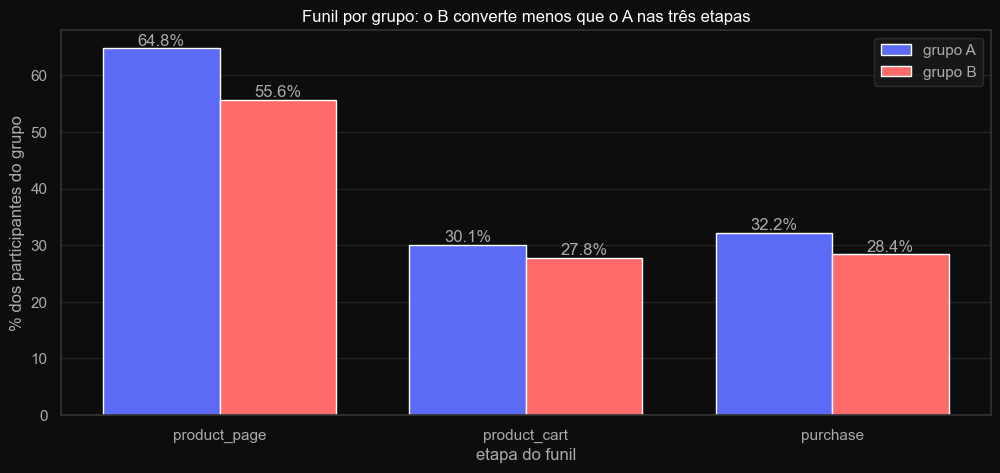

In [475]:
# 3. gráfico do funil: % de cada grupo que chega a cada etapa, A em azul e B em vermelho
PASTA_IMAGENS = 'images'
os.makedirs(PASTA_IMAGENS, exist_ok=True)
COR_GRUPO = {'A': CORES[0], 'B': CORES[1]}

# barras lado a lado: cada grupo desloca meia largura para um lado da posição da etapa
posicoes = np.arange(len(ETAPAS))
largura = 0.38
fig, ax = plt.subplots()
for deslocamento, grupo in [(-largura / 2, 'A'), (largura / 2, 'B')]:
    valores = funil[f'% {grupo} do total']
    barras = ax.bar(posicoes + deslocamento, valores, largura, color=COR_GRUPO[grupo], label=f'grupo {grupo}')
    # rótulo em cima de cada barra com ax.text (funciona em qualquer versão do matplotlib)
    for barra, valor in zip(barras, valores):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(), f'{valor:.1f}%',
                ha='center', va='bottom', color='#aaaaaa')

ax.set_xticks(posicoes)
ax.set_xticklabels(ETAPAS)
ax.set_title('Funil por grupo: o B converte menos que o A nas três etapas')
ax.set_xlabel('etapa do funil')
ax.set_ylabel('% dos participantes do grupo')
ax.legend()
plt.savefig(f'{PASTA_IMAGENS}/funil_por_grupo.png')
plt.show()

In [476]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 4. funil no formato de funil (go.Funnel), um painel por grupo
#    a largura é a % do total do grupo, e não o número de usuários: assim o B, que é menor, fica comparável ao A
#    o rótulo é montado à mão (usuários e %), porque o textinfo do plotly sai em inglês
fig = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=['grupo A', 'grupo B'])
for coluna, grupo in enumerate(['A', 'B'], start=1):
    rotulos = [f'{usuarios} usuários<br>{pct:.1f}%'.replace('.', ',')
            for usuarios, pct in zip(funil[f'usuários {grupo}'], funil[f'% {grupo} do total'])]
    fig.add_trace(go.Funnel(
        name=f'grupo {grupo}',
        y=ETAPAS,
        x=funil[f'% {grupo} do total'],
        text=rotulos,
        textinfo='text',
        textposition='inside',
        insidetextfont=dict(size=13, color='#ffffff'),
        marker=dict(color=COR_GRUPO[grupo]),
        connector=dict(line=dict(color='#333333')),
    ), row=1, col=coluna)

# matches='x' põe os dois painéis na mesma escala: sem isso o topo do B pareceria do tamanho do A
fig.update_xaxes(matches='x')
fig.update_layout(
    template='plotly_dark',
    title='Funil por grupo: o B converte menos que o A em todas as etapas',
    paper_bgcolor='#0d0d0d', plot_bgcolor='#0d0d0d', showlegend=False,
    uniformtext=dict(minsize=12, mode='show'),
    width=1100, height=500, margin=dict(l=140, r=40, t=90, b=40),
)

fig.show()

**Conclusão 5.1 — o grupo B converte menos que o A nas três etapas, e o funil não é sequencial:**

+ **Funil sobre o total do grupo:** 1.476 usuários do A (64,77%) viram a página do produto, contra 429 do B (55,64%). No carrinho foram 686 do A (30,10%) e 214 do B (27,76%). Na compra, 734 do A (32,21%) e 219 do B (28,40%). O B fica abaixo do A em todas as etapas, o contrário do aumento de 10% que a loja esperava. A seção 6 testa se essas diferenças são estatisticamente significativas.

+ **O funil não é sequencial:** dos 953 usuários que compraram, 653 (68,52%) não passaram pelo carrinho e 316 (33,16%) não passaram pela página do produto. Por isso a coluna "da etapa anterior" passa de 100% na compra (107,00% no A e 102,34% no B): há mais compradores do que gente que pôs no carrinho. Pode existir um caminho de compra direta, mas os dados não dizem qual.

+ **O que isso muda na leitura:** como as etapas não seguem uma ordem fixa, a conversão "sobre a etapa anterior" engana. No teste da seção 6 uso a conversão sobre o total de participantes de cada grupo, que não depende da ordem.

## 5.2 Eventos por usuário e por dia

> *Enunciado: "O número de eventos por usuário está distribuído de forma equilibrada entre as amostras? Como os eventos estão distribuídos ao longo dos dias? Há peculiaridades que devem ser consideradas?"*

Primeiro comparo quantos eventos cada usuário faz em A e em B, com média e mediana, porque poucos usuários muito ativos podem puxar a média. Como os grupos têm tamanhos diferentes, o histograma usa a proporção de usuários e não a contagem. Depois olho os eventos e os cadastros por dia em cada grupo, com a campanha de Natal e Ano-Novo marcada em cinza. Os dois gráficos por dia têm o mesmo formato, então saem de uma função chamada num laço. No fim, junto as peculiaridades que mudam a leitura do teste.

In [477]:
# 1. eventos por usuário em cada grupo, dentro da janela
eventos_por_usuario = eventos_teste.groupby(['group', 'user_id'], observed=True).size().rename('eventos')
eventos_por_usuario.groupby(level='group', observed=True).describe().round(1)

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,2279.0,6.7,3.7,1.0,4.0,6.0,9.0,24.0
B,771.0,5.3,3.1,1.0,3.0,4.0,6.0,24.0


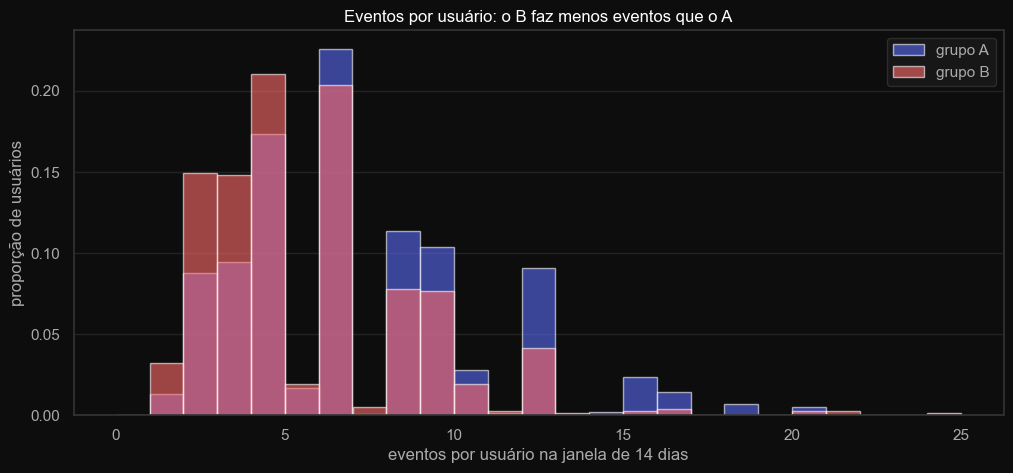

In [478]:
# 2. histograma dos eventos por usuário; density=True compara proporções, porque A é bem maior que B
fig, ax = plt.subplots()
for grupo in ['A', 'B']:
    ax.hist(eventos_por_usuario.loc[grupo], bins=range(0, eventos_por_usuario.max() + 2),
            density=True, alpha=0.6, color=COR_GRUPO[grupo], label=f'grupo {grupo}')
ax.set_title('Eventos por usuário: o B faz menos eventos que o A')
ax.set_xlabel('eventos por usuário na janela de 14 dias')
ax.set_ylabel('proporção de usuários')
ax.legend()
plt.savefig(f'{PASTA_IMAGENS}/eventos_por_usuario.png')
plt.show()

dias sem eventos: ['25/12', '30/12']


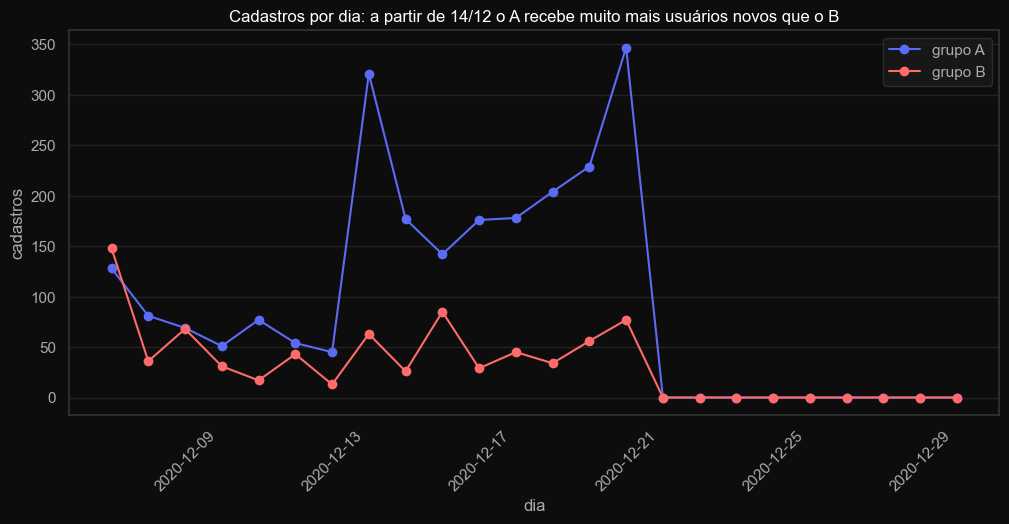

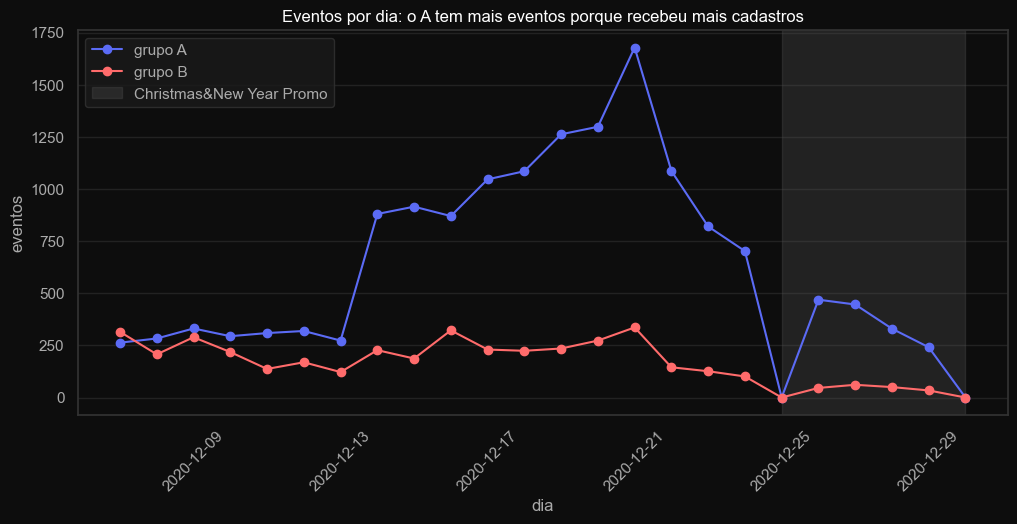

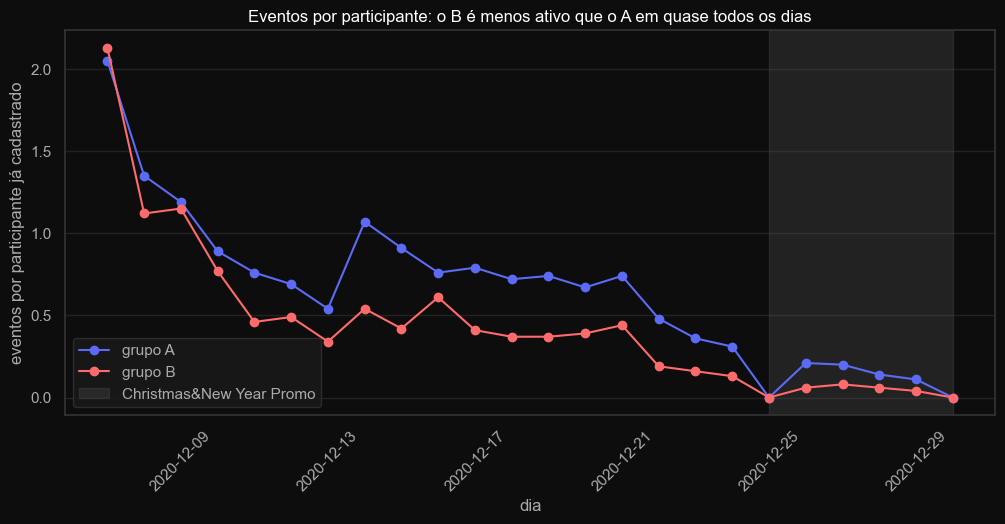

In [479]:
def plotar_por_dia(contagem, titulo, rotulo_y, arquivo, marcar_campanha=True):
    """Desenha uma linha por grupo ao longo dos dias, com a campanha de Natal e Ano-Novo em cinza.

    Parâmetros
    ----------
    contagem : DataFrame com os dias no índice e uma coluna por grupo ('A' e 'B').
    titulo : título do gráfico, escrito como conclusão.
    rotulo_y : nome do eixo y, com a unidade.
    arquivo : nome do arquivo .png salvo em PASTA_IMAGENS.
    marcar_campanha : se True, pinta o período da campanha que atinge a EU.

    Retorna
    -------
    None : salva e mostra o gráfico.
    """
    fig, ax = plt.subplots()
    for grupo in ['A', 'B']:
        ax.plot(contagem.index, contagem[grupo], marker='o', color=COR_GRUPO[grupo], label=f'grupo {grupo}')
    # faixa cinza da campanha que atinge a EU, cortada no último dia do gráfico (seção 4.2)
    if marcar_campanha:
        campanha = no_periodo[no_periodo['regions'].str.contains('EU')].iloc[0]
        ax.axvspan(campanha['start_dt'], min(campanha['finish_dt'], contagem.index.max()),
                   color='#555555', alpha=0.3, label=campanha['name'])
    ax.set_title(titulo)
    ax.set_xlabel('dia')
    ax.set_ylabel(rotulo_y)
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
    plt.savefig(f'{PASTA_IMAGENS}/{arquivo}')
    plt.show()


# 3. contagens por dia e grupo; o reindex põe 0 nos dias sem registro, que o groupby pularia
dias = pd.date_range(INICIO_CADASTRO, ultimo_dia, freq='D')
eventos_dia = (eventos_teste.groupby([eventos_teste['event_dt'].dt.normalize(), 'group'], observed=True)
               .size().unstack('group').reindex(dias, fill_value=0))
cadastros_dia = (teste.groupby(['first_date', 'group'], observed=True)
                 .size().unstack('group').reindex(dias, fill_value=0))

# eventos por participante já cadastrado: cumsum() acumula os cadastros até cada dia
# assim o A, que tem três vezes mais gente, fica comparável ao B
eventos_por_participante = (eventos_dia / cadastros_dia.cumsum()).round(2)

# dias sem eventos: o reindex deixa à vista
print('dias sem eventos:', [f'{dia:%d/%m}' for dia in eventos_dia.index[eventos_dia.sum(axis=1) == 0]])

# 4. um gráfico por contagem; a campanha só aparece onde há dias depois de 25/12
graficos_dia = [
    (cadastros_dia, 'Cadastros por dia: a partir de 14/12 o A recebe muito mais usuários novos que o B',
     'cadastros', 'cadastros_por_dia.png', False),
    (eventos_dia, 'Eventos por dia: o A tem mais eventos porque recebeu mais cadastros',
     'eventos', 'eventos_por_dia.png', True),
    (eventos_por_participante, 'Eventos por participante: o B é menos ativo que o A em quase todos os dias',
     'eventos por participante já cadastrado', 'eventos_por_participante_dia.png', True),
]
for contagem, titulo, rotulo_y, arquivo, marcar_campanha in graficos_dia:
    plotar_por_dia(contagem, titulo, rotulo_y, arquivo, marcar_campanha)

In [ ]:
# 5. dias zerados: a base inteira, antes de qualquer filtro, tem eventos em 25/12 e 30/12?
eventos_base_dia = events['event_dt'].dt.normalize().value_counts().reindex(dias, fill_value=0)
print(eventos_base_dia.loc['2020-12-23':'2020-12-30'])

# eventos por participante nos primeiros dias, para comparar o começo dos dois grupos
print(eventos_por_participante.head(3))

**Conclusão 5.2 — o B é menos ativo, os grupos entraram em ritmos diferentes e há dias sem nenhum evento:**

+ **Eventos por usuário:** no A a média é de 6,7 eventos e a mediana de 6; no B, média de 5,3 e mediana de 4. O máximo é 24 nos dois. A distribuição não é equilibrada: o histograma mostra o B concentrado entre 2 e 5 eventos e o A com mais usuários acima de 8.

+ **Cadastros por dia:** até 13/12 os dois grupos recebem quantidades parecidas de usuários novos. A partir de 14/12, o A recebe muito mais cadastros que o B, até o fim das inscrições em 21/12. Isso explica parte do desequilíbrio da seção 4.2 e por que mais gente do A ficou sem os 14 dias inteiros (seção 4.3).

+ **Eventos por dia:** em número absoluto, o A sobe a partir de 14/12 e tem o pico em 21/12, mas isso vem sobretudo de ele ter recebido mais cadastros. Por participante já cadastrado, os dois grupos começam iguais em 07/12 (2,05 eventos no A e 2,13 no B), e a partir de 10/12 o B fica abaixo do A em todos os dias. Depois de 21/12 os eventos caem nos dois grupos, porque não entra mais ninguém e as janelas de 14 dias vão vencendo; o Natal pode reforçar a queda, mas o gráfico não separa as duas causas.

+ **Dias sem eventos:** em 25/12 a base inteira não tem nenhum evento, nem antes dos filtros: é um buraco na coleta ou a loja parada, e os dados não dizem qual. Em 30/12 a base inteira tem só 89 eventos, contra 10.146 em 29/12, e os poucos eventos de participantes nesse dia caem fora da janela de 14 dias.

+ **Campanha:** no período da "Christmas&New Year Promo" (a partir de 25/12) os eventos ficam baixos nos dois grupos, sem um aumento visível.

**Peculiaridades antes do teste A/B:**
1. O funil não é sequencial, então comparo a conversão sobre o total do grupo (seção 5.1).
2. Os grupos têm tamanhos muito diferentes, e o sorteio não foi meio a meio (seção 4.2).
3. A partir de 14/12 os grupos receberam usuários em ritmos diferentes, o que deixa o A com mais janelas cortadas (seções 4.3 e 5.2).
4. O B é menos ativo em número de eventos por usuário.
5. Há dias sem nenhum evento (25/12 e 30/12) e os dados acabam antes do previsto.

Com isso, o teste Z da seção 6 mede a diferença entre os grupos, mas parte dela pode vir de como os grupos foram formados e não só da mudança testada.

---

# 6. Teste A/B

> **Enunciado:** usar o teste Z para verificar a diferença estatística entre proporções e justificar o método.

## 6.1 Teste Z por etapa do funil

Uso o teste Z de proporções porque, em cada etapa, a resposta de cada usuário é binária (chegou ou não chegou), os dois grupos são independentes, já que nenhum usuário está nos dois (seção 4.1), e grandes o bastante para a aproximação normal. Escrevo o teste numa função própria com docstring, na forma do material e da Sprint 11: proporção combinada no erro padrão e p-valor bilateral pela normal padrão. Com 3 comparações, aplico a correção de Bonferroni declarada na seção 1.2: o nível de 5% dividido por 3. Rodo o teste em duas versões, como decidi na seção 4.3: com todos os participantes e só com quem teve os 14 dias inteiros.

In [480]:
# 1. nível de significância e correção de Bonferroni para as 3 etapas (seção 1.2)
ALFA = 0.05
ALFA_BONFERRONI = ALFA / len(ETAPAS)
print(f'alfa: {ALFA} | alfa corrigido por Bonferroni: {ALFA_BONFERRONI:.4f}')

# função do teste Z: recebe só números (sucessos e tamanho de cada grupo) e devolve o resultado
# escrevo uma vez e uso nas 3 etapas e nas 2 versões, sem repetir a fórmula 6 vezes
def z_test_proporcoes(sucessos_a, n_a, sucessos_b, n_b):
    """Teste Z de duas proporções, bilateral, na forma do material: proporção combinada no erro padrão.

    Parâmetros
    ----------
    sucessos_a, n_a : usuários do grupo A que chegaram à etapa e total de usuários do grupo A.
    sucessos_b, n_b : o mesmo para o grupo B.

    Retorna
    -------
    dict : conversão de A e B (%), diferença em pontos percentuais e relativa (B sobre A), z e p-valor.
    """
    p_a = sucessos_a / n_a
    p_b = sucessos_b / n_b

    # proporção combinada dos dois grupos, usada no erro padrão sob H0 (proporções iguais)
    p_combinada = (sucessos_a + sucessos_b) / (n_a + n_b)
    erro_padrao = mth.sqrt(p_combinada * (1 - p_combinada) * (1 / n_a + 1 / n_b))

    # z: a quantos erros padrão a diferença está de zero; abs() e * 2 cobrem as duas caudas
    z = (p_b - p_a) / erro_padrao
    p_valor = (1 - stats.norm(0, 1).cdf(abs(z))) * 2

    return {'% A': round(p_a * 100, 2), '% B': round(p_b * 100, 2),
            'diferença (p.p.)': round((p_b - p_a) * 100, 2),
            'diferença relativa %': round((p_b / p_a - 1) * 100, 2),
            'z': round(z, 3), 'p-valor': p_valor}

alfa: 0.05 | alfa corrigido por Bonferroni: 0.0167


In [ ]:
# função que roda o teste nas 3 etapas para um conjunto de participantes
# chamo duas vezes (todos e só quem teve os 14 dias) e as duas tabelas saem no mesmo formato
def testar_funil(participantes, eventos, versao):
    """Roda o teste Z nas 3 etapas do funil para um conjunto de participantes.

    Parâmetros
    ----------
    participantes : DataFrame com user_id e group (a base de cada grupo).
    eventos : DataFrame de eventos na janela, com user_id, group e event_name.
    versao : nome da versão, para identificar as linhas da tabela.

    Retorna
    -------
    DataFrame : uma linha por etapa, com o resultado do teste e a decisão sobre H0.
    """
    tamanho = participantes['group'].value_counts()
    eventos = eventos[eventos['user_id'].isin(participantes['user_id'])]
    linhas = []
    for etapa in ETAPAS:
        # usuários únicos de cada grupo que chegaram à etapa
        chegaram = eventos[eventos['event_name'] == etapa].groupby('group', observed=True)['user_id'].nunique()
        resultado = z_test_proporcoes(chegaram['A'], tamanho['A'], chegaram['B'], tamanho['B'])
        linhas.append({'versão': versao, 'etapa': etapa, 'n A': tamanho['A'], 'n B': tamanho['B'], **resultado})
    tabela = pd.DataFrame(linhas)
    tabela['rejeita H0'] = tabela['p-valor'] < ALFA_BONFERRONI
    return tabela


# 2. as duas versões da seção 4.3: todos e só quem teve os 14 dias inteiros
janela_completa = teste[teste['first_date'] <= ultimo_cadastro_completo]
print(f'participantes com os 14 dias inteiros: {len(janela_completa)} de {len(teste)}')

resultados = pd.concat([testar_funil(teste, eventos_teste, 'todos'),
                        testar_funil(janela_completa, eventos_teste, '14 dias inteiros')],
                    ignore_index=True)
resultados

participantes com os 14 dias inteiros: 1880 de 3050


,versão,etapa,n A,n B,% A,% B,diferença (p.p.),diferença relativa %,z,p-valor,rejeita H0
0,todos,product_page,2279,771,64.77,55.64,-9.12,-14.09,-4.522,0.000006,True
1,todos,product_cart,2279,771,30.10,27.76,-2.34,-7.79,-1.234,0.217211,False
2,todos,purchase,2279,771,32.21,28.40,-3.80,-11.81,-1.969,0.048943,False
3,14 dias inteiros,product_page,1321,559,63.82,55.64,-8.18,-12.82,-3.330,0.000869,True
4,14 dias inteiros,product_cart,1321,559,30.81,29.34,-1.47,-4.78,-0.634,0.525858,False
5,14 dias inteiros,purchase,1321,559,30.66,28.09,-2.57,-8.39,-1.114,0.265369,False


**Conclusão 6.1 — o B converte significativamente menos na página do produto; no carrinho e na compra a diferença não é significativa:**

+ **Nível de significância:** com a correção de Bonferroni para 3 etapas, um resultado só é significativo com p-valor abaixo de 0,0167.

+ **Todos os participantes (A 2.279, B 771):**
  - `product_page`: 64,77% no A e 55,64% no B, uma diferença de -9,12 pontos percentuais (-14,09%). P-valor de 0,000006: rejeito H0. O B viu menos a página do produto.
  - `product_cart`: 30,10% no A e 27,76% no B (-2,34 p.p., -7,79%). P-valor de 0,217: não rejeito H0.
  - `purchase`: 32,21% no A e 28,40% no B (-3,80 p.p., -11,81%). P-valor de 0,049: fica abaixo de 5%, mas acima de 0,0167, então com a correção não rejeito H0.

+ **Só quem teve os 14 dias inteiros (A 1.321, B 559):** a decisão é a mesma nas três etapas. A página do produto continua significativa (p-valor de 0,000869), e o carrinho (0,526) e a compra (0,265) não. As diferenças relativas ficam um pouco menores, mas o sentido não muda.

+ **As duas versões concordam:** o corte de tempo da seção 4.3 não muda a conclusão. Em todas as etapas e nas duas versões o B fica abaixo do A, o contrário do que a loja esperava.

## 6.2 Comparação com o aumento esperado de 10%

A loja esperava que o B convertesse pelo menos 10% a mais que o A em cada etapa. Comparo a diferença relativa observada com esse aumento. Depois calculo o poder do teste: a chance de ele detectar um aumento de 10% com o tamanho que os grupos realmente tiveram. Se o poder for baixo, um resultado "não significativo" não quer dizer que a mudança não funciona, e sim que a amostra é pequena demais para ver.

In [ ]:
# 1. aumento esperado pela especificação, relativo à conversão do A
AUMENTO_ESPERADO = 0.10

# função do poder: a chance de o teste detectar um aumento de 10% com o tamanho real dos grupos
# uso para cada etapa e versão, a partir da conversão do A e do tamanho de cada grupo
def poder_teste(p_a, n_a, n_b, aumento, alfa):
    """Poder aproximado do teste Z bilateral para detectar um aumento relativo na conversão do B.

    Parâmetros
    ----------
    p_a : conversão do grupo A (proporção entre 0 e 1).
    n_a, n_b : tamanho dos grupos A e B.
    aumento : aumento relativo esperado no B (0.10 = 10%).
    alfa : nível de significância já corrigido.

    Retorna
    -------
    float : probabilidade de o teste rejeitar H0 se o aumento existir de verdade.
    """
    p_b = p_a * (1 + aumento)
    erro_padrao = mth.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    z_critico = stats.norm(0, 1).ppf(1 - alfa / 2)
    return 1 - stats.norm(0, 1).cdf(z_critico - (p_b - p_a) / erro_padrao)


# 2. para cada linha de resultados: o aumento observado contra os 10% e o poder do teste
comparacao = resultados[['versão', 'etapa', '% A', '% B', 'diferença relativa %']].copy()
comparacao['aumento esperado %'] = AUMENTO_ESPERADO * 100
comparacao['atingiu os 10%'] = comparacao['diferença relativa %'] >= AUMENTO_ESPERADO * 100
comparacao['poder para ver +10%'] = [
    round(poder_teste(linha['% A'] / 100, linha['n A'], linha['n B'], AUMENTO_ESPERADO, ALFA_BONFERRONI), 3)
    for _, linha in resultados.iterrows()]
comparacao

,versão,etapa,% A,% B,diferença relativa %,aumento esperado %,atingiu os 10%,poder para ver +10%
0,todos,product_page,64.77,55.64,-14.09,10.0,False,0.839
1,todos,product_cart,30.10,27.76,-7.79,10.0,False,0.198
2,todos,purchase,32.21,28.40,-11.81,10.0,False,0.221
3,14 dias inteiros,product_page,63.82,55.64,-12.82,10.0,False,0.629
4,14 dias inteiros,product_cart,30.81,29.34,-4.78,10.0,False,0.137
5,14 dias inteiros,purchase,30.66,28.09,-8.39,10.0,False,0.136


**Conclusão 6.2 — o aumento de 10% não aconteceu em nenhuma etapa, e no carrinho e na compra o teste mal teria poder para vê-lo:**

+ **Aumento esperado:** nenhuma das 6 comparações atingiu os 10%. Todas as diferenças relativas são negativas, de -4,78% a -14,09%: o B converteu menos que o A, e não mais.

+ **Poder do teste:** com o tamanho que os grupos realmente tiveram, a chance de detectar um aumento de 10% seria de 0,839 na página do produto, mas só de 0,198 no carrinho e de 0,221 na compra, considerando todos os participantes. Na versão só com os 14 dias inteiros, o poder cai para 0,629, 0,137 e 0,136. O valor usual de referência é 0,8.

+ **O que isso quer dizer:** na página do produto o teste tinha poder e encontrou uma queda significativa, então ali a evidência é forte. No carrinho e na compra, o "não significativo" não prova que não há efeito: com grupos deste tamanho, o teste dificilmente veria até um aumento real de 10%. Mesmo assim, a diferença observada vai na direção contrária, então os dados não dão nenhum sinal de que a mudança aumente a conversão.

---

# 7. Conclusão geral

> **Enunciado:** resumir as conclusões da EDA e dos resultados do teste A/B, com recomendações.

**Conclusão geral — o grupo B não converteu melhor, e o teste não foi feito como a especificação previa:**

1. **O teste não seguiu a especificação.** Teve metade dos participantes previstos, grupos muito desequilibrados, usuários de outro teste no meio e dados que acabam antes do fim.
2. **O grupo B não converteu melhor que o A.** Converteu menos nas três etapas, com queda significativa na página do produto e sem diferença significativa no carrinho e na compra. O aumento de 10% não apareceu em nenhuma etapa.
3. **Recomendo não lançar a mudança e refazer o teste**, corrigindo os problemas de desenho antes de decidir.

**O que a seção 4 encontrou no desenho do teste.** Dos 14.525 registros de participantes, 3.675 eram do `recommender_system_test` (seção 4.1). Desses, 887 (24,14%) também estavam no `interface_eu_test`, um teste paralelo que o enunciado não menciona, e saíram os 431 (11,73%) que receberam a mudança daquele teste (seção 4.1). Também saíram 194 participantes de fora da EU (seção 4.2). Ficaram 3.050, 50,83% dos 6.000 previstos, e o teste recebeu 8,82% dos novos usuários da EU, contra os 15% planejados (seção 4.2). O grupo A ficou com 74,72% dos participantes e o B com 25,28%, e o qui-quadrado contra a divisão 50/50 dá p-valor de 3,64e-164: o sorteio não foi meio a meio (seção 4.2). Os dados acabam em 30/12 e não em 01/01, e 1.170 participantes (38,36%) não tiveram os 14 dias inteiros, mais no A (42,04%) do que no B (27,50%) (seção 4.3).

**O que a análise exploratória mostrou.** O B fica abaixo do A em todas as etapas do funil: 55,64% contra 64,77% na página do produto, 27,76% contra 30,10% no carrinho e 28,40% contra 32,21% na compra (seção 5.1). O funil não é sequencial, porque 653 dos 953 compradores (68,52%) compraram sem passar pelo carrinho, então comparo a conversão sobre o total de cada grupo (seção 5.1). O B também é menos ativo, com mediana de 4 eventos por usuário contra 6 no A (seção 5.2). A partir de 14/12 o A passou a receber muito mais cadastros que o B, e em 25/12 a base inteira não tem nenhum evento (seção 5.2).

**O que o teste Z mostrou.** Com a correção de Bonferroni, o limite de significância é 0,0167 (seção 6.1). Na página do produto, a queda do B (-9,12 pontos percentuais, -14,09%) é significativa, com p-valor de 0,000006 (seção 6.1). No carrinho (p-valor de 0,217) e na compra (p-valor de 0,049) a diferença não é significativa (seção 6.1). Só com quem teve os 14 dias inteiros, as decisões são as mesmas, então o corte de tempo não muda o resultado (seção 6.1). Nenhuma etapa chegou ao aumento de 10% (seção 6.2).

**Limites desta conclusão.** O teste tinha pouco poder no carrinho e na compra: a chance de detectar um aumento real de 10% era de 0,198 e 0,221, contra a referência usual de 0,8 (seção 6.2). Por isso, ali, "não significativo" não prova ausência de efeito. Além disso, o desequilíbrio entre os grupos e os cadastros em ritmos diferentes mostram que os grupos não foram formados do mesmo jeito, e parte da diferença pode vir disso e não da mudança. O período de Natal e Ano-Novo e a campanha "Christmas&New Year Promo" também podem ter mudado o comportamento de todos no fim do teste (seções 4.2 e 5.2). E não está claro o que o grupo B recebeu: o nome fala em "novo funil de pagamento" e o objetivo em "sistema de recomendações" (seção 1.1).

**Recomendação.** Não lançar a mudança, porque nenhum resultado mostra ganho e a única diferença significativa é uma queda. Refazer o teste com: a mudança testada descrita com clareza; divisão de 50% para cada grupo, conferida durante o teste; nenhum outro teste rodando com os mesmos usuários; um período fora das festas de fim de ano; os dados coletados até 14 dias depois do último cadastro; e uma amostra calculada antes, grande o bastante para detectar 10% no carrinho e na compra.